# 01. BirdNET: from predictions to defensible observations

This notebook explains scores, thresholds, precision, recall and confidence intervals using the supplied data.
The take-home brief requires a species-specific **99% estimated probability of correctness** cutoff and a new
`observation` field. It also requires a Markdown explanation for the Tech team; the authored reports are in `reports/` and are preserved on rerun.

Read each section as **question -> reason -> code -> result -> decision**. Run from a fresh kernel, top to bottom.
Raw data are preserved. 

Calibration is exploratory: the same validation sample fits and diagnoses the model;
there is no independent test set or evidence here of calls BirdNET never reported.

**Simple explanation:** BirdNET gives each clip a score. An expert checks some clips. We use those checks to
learn what a score means for each species, then keep predictions whose fitted correctness probability reaches 99%.
An unconfirmed prediction does not mean the species was absent.

**Sources:** supplied take-home brief; Wood & Kahl (2024), DOI 10.1007/s10336-024-02144-5, in `data/reference/`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
assert (ROOT / 'src').is_dir(), 'Open Jupyter from the project root or notebooks folder.'
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.common import load_tables,profile,check_table,input_hashes,verify_raw_unchanged,save_evidence
RAW=ROOT/'data/raw'; OUT=ROOT/'outputs'; FIG=OUT/'figures'
FIG.mkdir(parents=True,exist_ok=True)
INPUT_HASHES=input_hashes(RAW)
pd.set_option('display.max_columns',30)
pd.set_option('display.max_colwidth',80)
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
SEED=42
print('Project:',ROOT.name)


Project: natural-state-take-home


In [2]:
raw=load_tables(RAW,['birdnet_predictions','validation_results'])
display(pd.DataFrame([{'table':k,'rows':len(d),'columns':d.shape[1]} for k,d in raw.items()]))

,table,rows,columns
0,birdnet_predictions,29491,13
1,validation_results,551,6


In [3]:
import statsmodels.api as sm
from src.birds import (TARGET_P,EPS,SENSITIVITY,to_logit,from_logit,fit_glm,threshold,fit_species_models,apply_support_policy,label_predictions,checked_cutoff_evidence,bin_weighted_precision)

## 1. Understand the rows and input quality

**Question:** What does one row represent, and are scores and expert labels valid?

**Why:** A wrong row definition or malformed score produces misleading observations.

**Decision:** Treat a row as a species prediction for a segment, not an individual bird or a distinct call.

**Result:** `29,491` predictions and `551` expert checks across four species; input row and score checks are shown below.



In [4]:
preds = raw["birdnet_predictions"].copy()
val = raw["validation_results"].copy()
print("predictions:", preds.shape, " validations:", val.shape)
display(profile(preds))
display(profile(val))

predictions: (29491, 13)  validations: (551, 6)


,dtype,non_null,null_pct,n_unique,example
selection,int64,29491,0.0,270,1
view,object,29491,0.0,1,Spectrogram 1
channel,int64,29491,0.0,1,1
begin_time_s,int64,29491,0.0,2826,889
end_time_s,int64,29491,0.0,2826,892
low_freq_hz,int64,29491,0.0,1,0
high_freq_hz,int64,29491,0.0,1,15000
common_name,object,29491,0.0,4,African Black-headed Oriole
species_code,object,29491,0.0,4,abhori1
confidence,float64,29491,0.0,7939,0.6278


,dtype,non_null,null_pct,n_unique,example
scientificName,object,551,0.0,4,Caprimulgus poliocephalus
commonName,object,551,0.0,4,Abyssinian Nightjar
vBirdNET,object,551,0.0,1,v2.4
filename,object,551,0.0,551,0.107_4_RBS21_20230630_190000.wav
confidence,float64,551,0.0,342,0.107
outcome,int64,551,0.0,2,1


In [5]:
preds["source_stem"] = preds["begin_path"].str.split("/").str[-1].str.replace(r"\.wav$", "", case=False, regex=True)
seg_species = preds.groupby(["begin_path", "begin_time_s"])["common_name"].nunique()

check_table({
    "pred: exact duplicate rows": preds.duplicated().sum(),
    "pred: duplicate (file, start, species)": preds.duplicated(["begin_path", "begin_time_s", "common_name"]).sum(),
    "pred: segment length != 3 s": (preds["end_time_s"] - preds["begin_time_s"] != 3).sum(),
    "pred: confidence outside [0, 1]": (~preds["confidence"].between(0, 1)).sum(),
    "pred: confidence == 1.0 (logit is infinite)": (preds["confidence"] == 1).sum(),
    "pred: folder != recorder in path": (preds["folder"] != preds["begin_path"].str.split("/").str[1]).sum(),
    "pred: segments with >1 species": (seg_species > 1).sum(),
    "val: duplicate filenames": val["filename"].duplicated().sum(),
    "val: outcome not in {0, 1}": (~val["outcome"].isin([0, 1])).sum(),
    "val: species not in predictions": (~val["commonName"].isin(preds["common_name"])).sum(),
    "val: BirdNET version != v2.4": (val["vBirdNET"] != "v2.4").sum(),
})

,problem_rows,ok
pred: exact duplicate rows,0,True
"pred: duplicate (file, start, species)",0,True
pred: segment length != 3 s,0,True
"pred: confidence outside [0, 1]",0,True
pred: confidence == 1.0 (logit is infinite),4,False
pred: folder != recorder in path,0,True
pred: segments with >1 species,3,False
val: duplicate filenames,0,True
"val: outcome not in {0, 1}",0,True
val: species not in predictions,0,True


## 2. Explore predictions and validation coverage

**Question:** Do species have different score patterns and validation support?

**Why:** A common cutoff can behave very differently between species.

**Decision:** Fit by species; filename time is the recorder clock, with timezone unverified.

**Result:** Species differ in score distribution and correctness; Oriole has no observed errors and Plover has one.




In [6]:
stamp = preds["source_stem"].str.extract(r"_(\d{8})_(\d{6})$")
preds["recording_start"] = pd.to_datetime(stamp[0] + stamp[1], format="%Y%m%d%H%M%S")
preds["detection_time"] = preds["recording_start"] + pd.to_timedelta(preds["file_offset_s"], unit="s")

pred_summary = (preds.groupby("common_name")
    .agg(n_predictions=("confidence", "size"), n_recorders=("folder", "nunique"),
         first_day=("recording_start", "min"), last_day=("recording_start", "max"),
         conf_min=("confidence", "min"), conf_median=("confidence", "median"), conf_max=("confidence", "max"))
    .sort_values("n_predictions", ascending=False))
pred_summary

,n_predictions,n_recorders,first_day,last_day,conf_min,conf_median,conf_max
common_name,,,,,,,
African Black-headed Oriole,18054,35,2023-06-20 18:00:00,2023-07-12 18:00:00,0.1000,0.2787,0.9985
Abyssinian Nightjar,10187,27,2023-06-21 19:00:00,2023-07-11 21:00:00,0.1000,0.3223,1.0000
Three-banded Plover,1015,22,2023-06-22 17:00:00,2023-07-10 06:00:00,0.1002,0.2858,0.9997
Red-billed Firefinch,235,31,2023-06-20 07:00:00,2023-07-12 16:00:00,0.1000,0.1369,0.9073


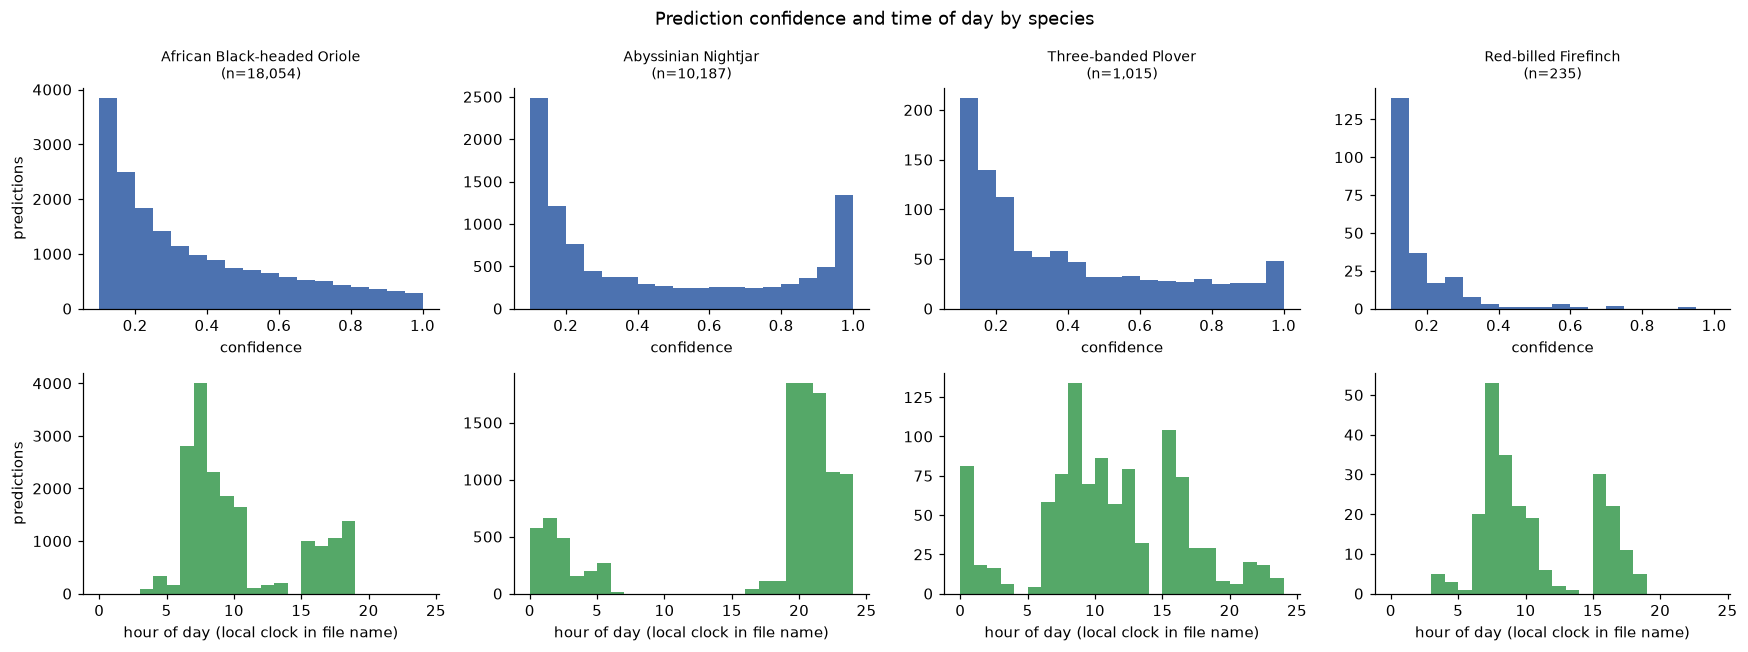

In [7]:
species_order = pred_summary.index.tolist()
fig, axes = plt.subplots(2, len(species_order), figsize=(16, 6))
for i, sp in enumerate(species_order):
    d = preds[preds["common_name"] == sp]
    axes[0, i].hist(d["confidence"], bins=np.linspace(0.1, 1, 19), color="#4C72B0")
    axes[0, i].set_title(f"{sp}\n(n={len(d):,})", fontsize=9)
    axes[0, i].set_xlabel("confidence")
    axes[1, i].hist(d["detection_time"].dt.hour, bins=range(25), color="#55A868")
    axes[1, i].set_xlabel("hour of day (local clock in file name)")
axes[0, 0].set_ylabel("predictions"); axes[1, 0].set_ylabel("predictions")
fig.suptitle("Prediction confidence and time of day by species")
fig.tight_layout(); fig.savefig(FIG / "A2_prediction_eda.png")

In [10]:
val_summary = (val.groupby("commonName")
    .agg(n_validated=("outcome", "size"), n_correct=("outcome", "sum"),
         conf_min=("confidence", "min"), conf_max=("confidence", "max"))
    .assign(pct_correct=lambda d: (100 * d["n_correct"] / d["n_validated"]).round(1),
            n_wrong=lambda d: d["n_validated"] - d["n_correct"]))
val_summary = val_summary.join(pred_summary[["n_predictions"]]).assign(
    pct_of_predictions_validated=lambda d: (100 * d["n_validated"] / d["n_predictions"]).round(2))
val_summary.loc[species_order]

,n_validated,n_correct,conf_min,conf_max,pct_correct,n_wrong,n_predictions,pct_of_predictions_validated
commonName,,,,,,,,
African Black-headed Oriole,150,150,0.104,0.989,100.0,0,18054,0.83
Abyssinian Nightjar,150,117,0.102,1.000,78.0,33,10187,1.47
Three-banded Plover,150,149,0.102,0.994,99.3,1,1015,14.78
Red-billed Firefinch,101,6,0.101,0.907,5.9,95,235,42.98


In [11]:
# Is the validation sample spread like the predictions (random) or deliberately spread across scores (stratified)?
bins = np.round(np.arange(0.1, 1.01, 0.1), 1)
val["conf_bin"] = pd.cut(val["confidence"], bins, include_lowest=True)
preds["conf_bin"] = pd.cut(preds["confidence"], bins, include_lowest=True)
binned = (val.groupby(["commonName", "conf_bin"], observed=False)
    .agg(n_val=("outcome", "size"), n_correct=("outcome", "sum"))
    .join(preds.groupby(["common_name", "conf_bin"], observed=False).size().rename("n_pred")
          .rename_axis(["commonName", "conf_bin"])))
binned["pct_correct"] = (100 * binned["n_correct"] / binned["n_val"]).round(1)
binned.unstack("commonName")[["n_pred", "n_val", "pct_correct"]]

n_pred                              \
commonName   Abyssinian Nightjar African Black-headed Oriole   
conf_bin                                                       
(0.099, 0.2]                3693                        6344   
(0.2, 0.3]                  1211                        3253   
(0.3, 0.4]                   748                        2131   
(0.4, 0.5]                   559                        1611   
(0.5, 0.6]                   484                        1339   
(0.6, 0.7]                   518                        1091   
(0.7, 0.8]                   494                         933   
(0.8, 0.9]                   647                         750   
(0.9, 1.0]                  1833                         602   

                                                                    n_val  \
commonName   Red-billed Firefinch Three-banded Plover Abyssinian Nightjar   
conf_bin                                                                    
(0.099, 0.2]                  177                 352                  43   
(0.2, 0.3]                     37                 170                  11   
(0.3, 0.4]                     11                 110                   5   
(0.4, 0.5]                      2                  79                   6   
(0.5, 0.6]                      4                  65                   5   
(0.6, 0.7]                      1                  57                   6   
(0.7, 0.8]                      2                  57                  10   
(0.8, 0.9]                      0                  51                  10   
(0.9, 1.0]                      1                  74                  54   

                                                               \
commonName   African Black-headed Oriole Red-billed Firefinch   
conf_bin                                                        
(0.099, 0.2]                          33                   77   
(0.2, 0.3]                            16                   14   
(0.3, 0.4]                            14                    6   
(0.4, 0.5]                            10                    1   
(0.5, 0.6]                             4                    2   
(0.6, 0.7]                             6                    0   
(0.7, 0.8]                             5                    0   
(0.8, 0.9]                            26                    0   
(0.9, 1.0]                            36                    1   

                                         pct_correct  \
commonName   Three-banded Plover Abyssinian Nightjar   
conf_bin                                               
(0.099, 0.2]                  39                32.6   
(0.2, 0.3]                    15                72.7   
(0.3, 0.4]                     7                80.0   
(0.4, 0.5]                     7               100.0   
(0.5, 0.6]                     8               100.0   
(0.6, 0.7]                     4               100.0   
(0.7, 0.8]                     6               100.0   
(0.8, 0.9]                    23               100.0   
(0.9, 1.0]                    41               100.0   

                                                               \
commonName   African Black-headed Oriole Red-billed Firefinch   
conf_bin                                                        
(0.099, 0.2]                       100.0                  5.2   
(0.2, 0.3]                         100.0                  7.1   
(0.3, 0.4]                         100.0                  0.0   
(0.4, 0.5]                         100.0                  0.0   
(0.5, 0.6]                         100.0                  0.0   
(0.6, 0.7]                         100.0                  NaN   
(0.7, 0.8]                         100.0                  NaN   
(0.8, 0.9]                         100.0                  NaN   
(0.9, 1.0]                         100.0                100.0   

                                  
commonName   Three-banded Plover  
conf_bin                   

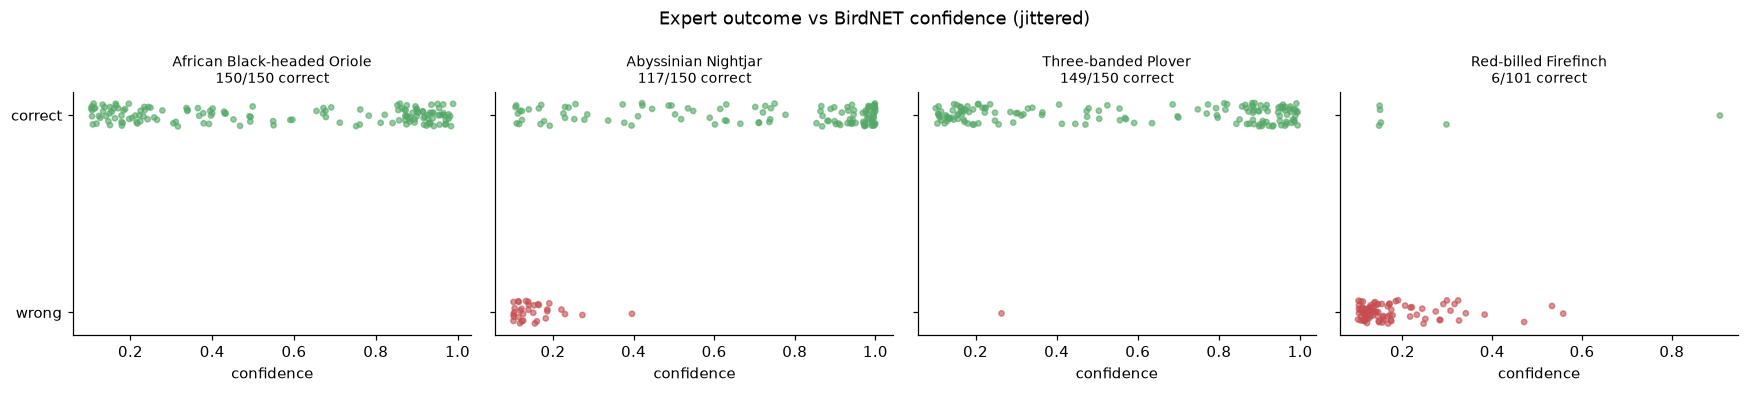

In [12]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, len(species_order), figsize=(16, 3.6), sharey=True)
for ax, sp in zip(axes, species_order):
    d = val[val["commonName"] == sp]
    jitter = rng.uniform(-0.06, 0.06, len(d))
    ax.scatter(d["confidence"], d["outcome"] + jitter, s=12, alpha=0.6,
               c=np.where(d["outcome"] == 1, "#55A868", "#C44E52"))
    ax.set_title(f"{sp}\n{int(d['outcome'].sum())}/{len(d)} correct", fontsize=9)
    ax.set_xlabel("confidence"); ax.set_yticks([0, 1], ["wrong", "correct"])
fig.suptitle("Expert outcome vs BirdNET confidence (jittered)")
fig.tight_layout(); fig.savefig(FIG / "A3_validation_outcomes.png")


**Interpretation:** Compare the number of errors and score range for each species. No observed errors does not prove
100% correctness. A single observed error provides weak information about the high-score error rate. The score-bin
table helps describe coverage; it does not prove how clips were selected. Ask for the validation sampling design,
deployment metadata, BirdNET sensitivity, and original clip identifiers before production deployment.

## 3. Audit validation linkage

**Question:** Can each validated clip be matched unambiguously to a prediction?

**Why:** Clip filenames contain a score and source recording, but a clip index is not a verified segment offset.

**Decision:** Audit candidates; do not apply expert overrides based on this approximate match.

**Result:** 205 unique candidate links, 302 unmatched validations and 44 ambiguous validations; no expert overrides.

In [13]:
v = val.reset_index(names="val_row")
parts = v["filename"].str.replace(r"\.wav$", "", case=False, regex=True).str.split("_", n=2, expand=True)
v["file_conf"] = parts[0].astype(float)
v["clip_idx"] = parts[1].astype(int)
v["source_stem"] = parts[2]

cand = v.merge(
    preds.reset_index(names="pred_row")[["pred_row", "source_stem", "common_name", "confidence", "begin_time_s"]],
    left_on=["source_stem", "commonName"], right_on=["source_stem", "common_name"],
    suffixes=("_val", "_pred"))
cand = cand[(cand["confidence_val"] - cand["confidence_pred"]).abs() <= 0.0005]
n_matches = cand.groupby("val_row").size().reindex(v["val_row"], fill_value=0)

print("file-name confidence == confidence column:", (v["file_conf"] == v["confidence"]).mean().round(3))
print("validated clips by number of matching predictions:")
print(n_matches.value_counts().sort_index().rename("n_val_clips").to_string())
val_links = cand[cand["val_row"].isin(n_matches[n_matches == 1].index)][["val_row", "pred_row", "outcome"]]
print("unique links:", len(val_links))

file-name confidence == confidence column: 1.0
validated clips by number of matching predictions:
0     302
1     205
2      25
3       7
4       5
5       1
6       1
7       1
8       2
10      1
11      1
unique links: 205


In [14]:
link_audit = pd.DataFrame({'validation_row': v['val_row'], 'candidate_matches': n_matches.values})
link_audit.to_csv(OUT / 'bird_validation_link_audit.csv', index=False)
display(link_audit['candidate_matches'].value_counts().sort_index())
print('This is a candidate-link audit, not a verified join on a stable clip ID.')

candidate_matches
0     302
1     205
2      25
3       7
4       5
5       1
6       1
7       1
8       2
10      1
11      1
Name: count, dtype: int64

This is a candidate-link audit, not a verified join on a stable clip ID.


**Interpretation:** Zero candidates do not establish that a clip came from a different run. Several candidates mean
ambiguity. Both cases limit expert overrides and raise a question about validation provenance and transferability.
The calibration fit uses validation score/outcome pairs directly and does not depend on this candidate join.

## 4. Explain the metrics before modelling

**Question:** What can these expert checks tell us?

**Why:** This prevents confusing prediction quality with missed real calls.

**Decision:** Compute precision among checked predictions; report recall as unavailable.

**Result:** Checked-sample precision is 78.0% for Nightjar; its bin-weighted estimate is about 70.8%, conditional on sampling assumptions. Recall is unavailable.

In [15]:
from statsmodels.stats.proportion import proportion_confint

metric_rows = []
for sp, d in val.groupby('commonName'):
    correct, total = int(d['outcome'].sum()), len(d)
    lower, upper = proportion_confint(correct, total, alpha=0.05, method='wilson')
    metric_rows.append({'species': sp, 'checked': total, 'correct': correct,
                        'sample_precision': correct / total, 'wilson_95_lower': lower,
                        'wilson_95_upper': upper, 'recall': np.nan})
metrics = pd.DataFrame(metric_rows)
display(metrics)
metrics.to_csv(OUT / 'bird_validation_metrics.csv', index=False)

,species,checked,correct,sample_precision,wilson_95_lower,wilson_95_upper,recall
0,Abyssinian Nightjar,150,117,0.780000,0.707177,0.838840,NaN
1,African Black-headed Oriole,150,150,1.000000,0.975030,1.000000,NaN
2,Red-billed Firefinch,101,6,0.059406,0.027508,0.123591,NaN
3,Three-banded Plover,150,149,0.993333,0.963207,0.998822,NaN


In [16]:
weighted_precision,weighted_bins=bin_weighted_precision(val,preds)
display(weighted_precision)
weighted_precision.to_csv(OUT/'bird_bin_weighted_precision.csv',index=False)
weighted_bins.to_csv(OUT/'bird_validation_score_bins.csv',index=False)

,species,checked_sample_precision,covered_prediction_share,weighted_estimate_covered_bins,uncovered_prediction_share,missing_bin_scenario_low,missing_bin_scenario_high
0,Abyssinian Nightjar,0.780000,1.000000,0.708403,0.000000,0.708403,0.708403
1,African Black-headed Oriole,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000
2,Red-billed Firefinch,0.059406,0.987234,0.055335,0.012766,0.054628,0.067394
3,Three-banded Plover,0.993333,1.000000,0.988834,0.000000,0.988834,0.988834


**Interpretation:** Bin weighting assumes checked clips represent correctness within score bins and that validation applies to this prediction population. Nightjar's checked-sample estimate is 78.0%, while its bin-weighted estimate is about 70.8%. Firefinch has unchecked bins containing about 1.3% of predictions. The scenario bounds fill those missing bins with 0% or 100% correctness; they are not confidence intervals. Oriole's weighted 100% is still a sample estimate, not certainty.

**Memory aid:** P = Predicted; R = Real. Precision asks: "Of the clips BirdNET reported, how many were correct?"
Recall asks: "Of all the genuine calls, how many did BirdNET find?" Recall needs independently labelled audio
including missed calls. The fraction of correct validated predictions retained by a cutoff is not ecological recall.

**Three different quantities:** a raw score is the classifier output; fitted `p_correct` is a model estimate;
a 95% interval describes estimation uncertainty under sampling assumptions. These Wilson intervals describe
the checked sample. They do not automatically estimate population precision when validation was score-stratified
or clips were correlated. This interval illustrates uncertainty in the checked sample, not the fitted cutoff.

## 5. Fit the relationship required by the brief

**Question:** What score corresponds to fitted 99% correctness for each species?

**Why:** A raw score of 0.99 is not the same as 99% correctness.

**Decision:** Use binomial GLM: expert outcome ~ logit(score), separately by species; clip boundaries at 1e-4.

**Result:** Ordinary GLM score cutoffs are approximately 0.667 for Nightjar and 0.259 for Plover; Oriole cannot be fitted and Firefinch requires extrapolation.

The GLM fits `logit(p_correct) = b0 + b1 * logit(score)`. Solving for p = 0.99 gives
`score_cutoff = sigmoid((logit(0.99) - b0) / b1)` when the fitted slope is positive.
Scores are clipped before transformation; sensitivity 1.0 is assumed and requires metadata confirmation.

In [17]:
val['logit']=to_logit(val['confidence'])
preds['logit']=to_logit(preds['confidence'])
models=fit_species_models(val,preds,species_order)
display(models)

,n,n_correct,separation,fit_status,logit_threshold,conf_threshold,threshold_within_val_range,n_preds_above,b0,b1,se_b1,converged,aic,p_slope
species,,,,,,,,,,,,,,
African Black-headed Oriole,150,150,single outcome,not fitted: single outcome,NaN,NaN,False,0,NaN,NaN,NaN,NaN,NaN,NaN
Abyssinian Nightjar,150,117,overlap (27 wrong ≥ lowest correct),ok,0.693018,0.666638,True,3147,3.158998,2.072270,0.495506,True,79.590344,0.000029
Three-banded Plover,150,149,overlap (1 wrong ≥ lowest correct),ok,-1.052204,0.258802,True,538,5.170345,0.546686,0.767319,True,15.231429,0.476178
Red-billed Firefinch,101,6,overlap (40 wrong ≥ lowest correct),ok,6.423567,0.998380,False,0,-1.457779,0.942296,0.446473,True,45.202668,0.034812


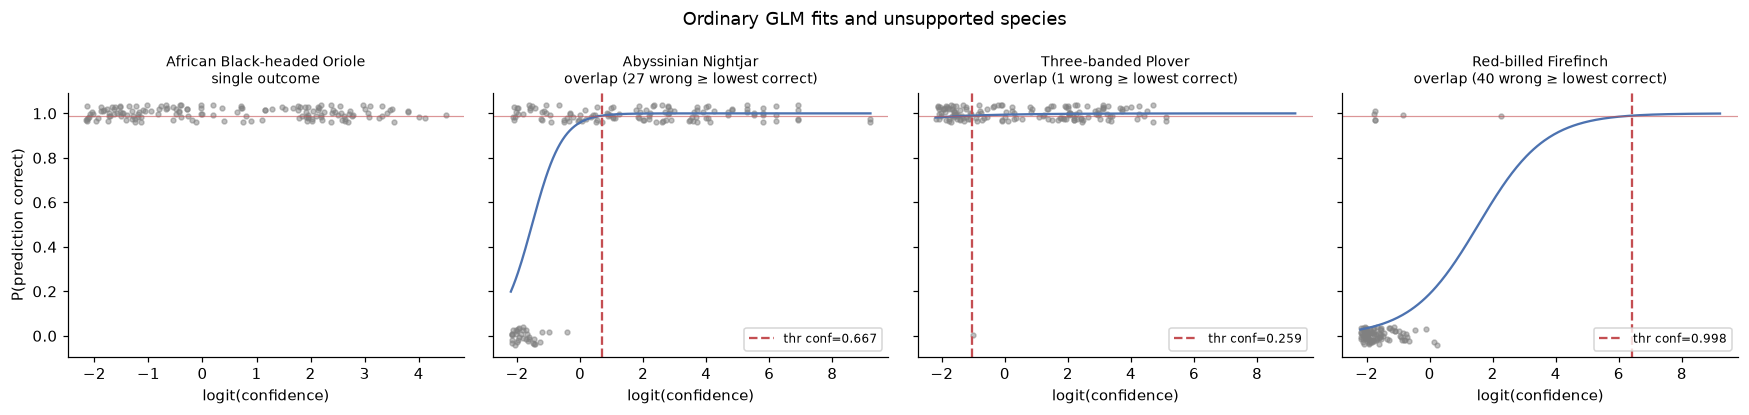

In [16]:
grid = np.linspace(to_logit(0.1), to_logit(0.9999), 300)
fig, axes = plt.subplots(1, len(species_order), figsize=(16, 3.8), sharey=True)
for ax, sp in zip(axes, species_order):
    d = val[val["commonName"] == sp]
    ax.scatter(d["logit"], d["outcome"] + rng.uniform(-0.04, 0.04, len(d)), s=10, alpha=0.5, color="grey")
    m = models.loc[sp]
    if pd.notna(m.get("b1")):
        ax.plot(grid, from_logit(m["b0"] + m["b1"] * grid), color="#4C72B0")
    if pd.notna(m["logit_threshold"]):
        ax.axvline(m["logit_threshold"], color="#C44E52", ls="--",
                   label=f"thr conf={m['conf_threshold']:.3f}")
        ax.legend(fontsize=8, loc="lower right")
    ax.axhline(TARGET_P, color="#C44E52", lw=0.8, alpha=0.6)
    ax.set_title(f"{sp}\n{m['separation']}", fontsize=9)
    ax.set_xlabel("logit(confidence)")
axes[0].set_ylabel("P(prediction correct)")
fig.suptitle("Ordinary GLM fits and unsupported species")
fig.tight_layout(); fig.savefig(FIG / "A5_baseline_fits.png")

## 6. Decide which fitted thresholds are supported

**Question:** Does each species provide enough evidence to use its fitted cutoff?

**Why:** The model can fail with one outcome class or put a cutoff outside validated scores.

**Decision:** Use the ordinary GLM for labels and a separate Firth fit to diagnose estimator sensitivity. Keep unsupported species and sparse-error candidates unconfirmed.

**Result:** Only Nightjar is eligible under the exploratory acceptance policy; Plover remains pending review.

In [18]:
thresholds=apply_support_policy(models,val)
display(thresholds[['n','n_wrong','conf_threshold','p_slope','status','use_for_labels']])
cutoff_evidence=checked_cutoff_evidence(val,thresholds)
display(cutoff_evidence)
cutoff_evidence.to_csv(OUT/'bird_checked_cutoff_evidence.csv',index=False)

,n,n_wrong,conf_threshold,p_slope,status,use_for_labels
species,,,,,,
African Black-headed Oriole,150,0,NaN,NaN,unsupported_fit,False
Abyssinian Nightjar,150,33,0.666638,0.000029,supported_exploratory_fit,True
Three-banded Plover,150,1,0.258802,0.476178,pending_review_sparse_errors,False
Red-billed Firefinch,101,95,0.998380,0.034812,unsupported_target_outside_validation_range,False


,species,evaluation_scope,cutoff,checked,correct,precision,one_sided_95_lower,use_for_labels
0,Abyssinian Nightjar,at_fitted_cutoff,0.666638,74,74,1.00,0.960326,True
1,African Black-headed Oriole,all_checked_scores,NaN,150,150,1.00,0.980227,False
2,Red-billed Firefinch,at_fitted_cutoff,0.998380,0,0,NaN,NaN,False
3,Three-banded Plover,at_fitted_cutoff,0.258802,100,99,0.99,0.953440,False


**Decision:** Plover has one observed error and an unstable fitted threshold. Its 0.259 cutoff remains exploratory, and its candidate predictions remain unconfirmed in the final observation field. Five errors is a screening heuristic, not a universal scientific release rule; slope significance alone is not a release criterion.

Oriole's 150/150 checks provide strong sample evidence, but one outcome class cannot identify the ordinary increasing logistic relationship. Firefinch's fitted cutoff lies outside validation support. An alternative method would require its own justification. The exact lower bounds shown above are checked-sample diagnostics; thresholds were fitted on the same data and clips may be correlated. They are not independent certification of 99% precision.

**Estimator sensitivity:** The reproducible Firth fit below moves Nightjar's cutoff from 0.667 to 0.709 (3,147 versus 2,931 candidates), and Plover's from 0.259 to 0.817 (538 versus 114 candidates). This is a diagnostic comparison, not evidence that either estimator certifies 99% precision. Oriole's ordinary GLM slope is not estimable with one outcome class; its Firth estimate is slightly negative (about -0.057), so it has no increasing cutoff. Firth does not change the observation labels. Boundary-clipping sensitivity in Section 7 tests a different issue.

Oriole's 150/150 correct checks give a one-sided exact 95% lower bound of about 98.0%. About 299 error-free checks are needed for that bound to reach 99%, assuming independent, representative checks at a prespecified cutoff. Fitting and evaluating a cutoff on the same clips adds selection optimism. This bound is an additional evidential standard, not the brief's fitted-probability requirement. Zero Oriole observations reflect the selected method's limit, not evidence of absence.

In [19]:
from src.birds import firth_sensitivity

firth = firth_sensitivity(val, preds)
firth = firth.join(thresholds[['conf_threshold']].rename(columns={'conf_threshold': 'glm_conf_threshold'}))
display(firth.round(4))
assert firth['firth_converged'].all(), 'A sensitivity fit did not converge; inspect its diagnostics.'
assert not firth['used_for_observation_labels'].any()
firth.to_csv(OUT / 'bird_firth_sensitivity.csv')
print('Firth sensitivity exported; the ordinary GLM observation policy is unchanged.')

,firth_b0,firth_b1,firth_conf_threshold,firth_candidates,firth_converged,firth_fit_status,firth_iterations,firth_max_abs_modified_score,firth_threshold_status,target_p,used_for_observation_labels,glm_conf_threshold
species,,,,,,,,,,,,
Abyssinian Nightjar,2.8964,1.9121,0.7086,2931,True,converged,14,0.0,sensitivity_only,0.99,False,0.6666
African Black-headed Oriole,5.0541,-0.0571,NaN,0,True,converged,18,0.0,no_increasing_cutoff,0.99,False,NaN
Red-billed Firefinch,-1.4510,0.8701,0.9990,0,True,converged,16,0.0,sensitivity_only,0.99,False,0.9984
Three-banded Plover,4.2684,0.2180,0.8174,114,True,converged,16,0.0,sensitivity_only,0.99,False,0.2588


Firth sensitivity exported; the ordinary GLM observation policy is unchanged.


## 7. Show uncertainty and numerical sensitivity

**Question:** How stable is the result, and what does the model interval mean?

**Why:** A fitted 0.99 probability alone does not establish a guaranteed 99% population precision.

**Decision:** Show pointwise GLM mean-probability intervals and compare boundary clipping choices.

**Result:** Plover has wide model uncertainty. Clipping sensitivity is tabulated separately from estimator sensitivity.

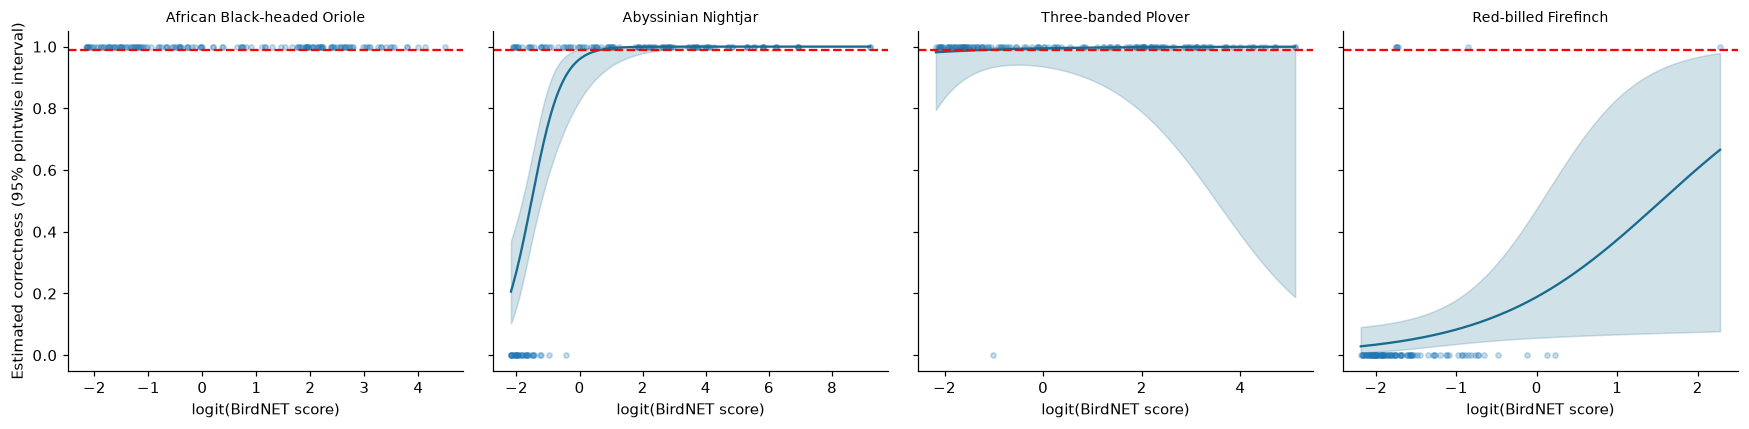

eps,1.000000e-08,1.000000e-06,1.000000e-04
species,,,
Abyssinian Nightjar,0.666638,0.666638,0.666638
African Black-headed Oriole,NaN,NaN,NaN
Red-billed Firefinch,0.998380,0.998380,0.998380
Three-banded Plover,0.258802,0.258802,0.258802


In [20]:
fig, axes = plt.subplots(1, len(species_order), figsize=(16, 4), sharey=True)
for ax, sp in zip(axes, species_order):
    d = val[val['commonName'] == sp]
    ax.scatter(d['logit'], d['outcome'], alpha=.25, s=12)
    r = thresholds.loc[sp]
    if r.get('fit_status') == 'ok' and r.get('converged', False):
        fit = sm.GLM(d['outcome'], sm.add_constant(d['logit']), family=sm.families.Binomial()).fit()
        gx = np.linspace(d['logit'].min(), d['logit'].max(), 200)
        pr = fit.get_prediction(sm.add_constant(gx)).summary_frame(alpha=.05)
        ax.plot(gx, pr['mean'], color='#186b8e')
        ax.fill_between(gx, pr['mean_ci_lower'], pr['mean_ci_upper'], color='#186b8e', alpha=.2)
    ax.axhline(.99, color='red', linestyle='--')
    ax.set_title(sp, fontsize=9); ax.set_xlabel('logit(BirdNET score)')
axes[0].set_ylabel('Estimated correctness (95% pointwise interval)')
fig.tight_layout(); fig.savefig(FIG / 'A7_probability_intervals.png'); plt.show()
sensitivity_rows = []
for eps in [1e-4, 1e-6, 1e-8]:
    for sp, d0 in val.groupby('commonName'):
        d = d0.copy(); d['logit'] = to_logit(d['confidence'], eps=eps)
        r = fit_glm(d)
        sensitivity_rows.append({'species': sp, 'eps': eps, 'score_cutoff': from_logit(threshold(r.get('b0'), r.get('b1'))), 'fit_status': r['fit_status']})
sensitivity_table = pd.DataFrame(sensitivity_rows)
display(sensitivity_table.pivot(index='species', columns='eps', values='score_cutoff'))
sensitivity_table.to_csv(OUT / 'bird_clipping_sensitivity.csv', index=False)

## 8. Compare cutoffs on the checked sample

**Question:** What happens when the acceptance cutoff rises?

**Why:** Higher cutoffs retain fewer predictions; checked-sample precision need not rise monotonically.

**Decision:** Treat this as an in-sample diagnostic, not an independent performance test.

**Result:** Raw-score cutoffs change retained counts and checked-sample precision; this diagnostic is in-sample.

In [21]:
tradeoff = []
for sp, d in val.groupby('commonName'):
    for cut in [.1,.3,.5,.7,.9,.99]:
        retained = d[d['confidence'] >= cut]
        tradeoff.append({'species':sp, 'raw_score_cutoff':cut, 'checked_retained':len(retained),
                         'checked_precision':retained['outcome'].mean(),
                         'all_predictions_retained':int(((preds['common_name']==sp)&(preds['confidence']>=cut)).sum())})
tradeoff = pd.DataFrame(tradeoff)
display(tradeoff)
tradeoff.to_csv(OUT / 'bird_raw_cutoff_diagnostic.csv', index=False)

,species,raw_score_cutoff,checked_retained,checked_precision,all_predictions_retained
0,Abyssinian Nightjar,0.10,150,0.780000,10187
1,Abyssinian Nightjar,0.30,96,0.989583,5284
2,Abyssinian Nightjar,0.50,85,1.000000,3977
3,Abyssinian Nightjar,0.70,74,1.000000,2974
4,Abyssinian Nightjar,0.90,54,1.000000,1834
5,Abyssinian Nightjar,0.99,22,1.000000,596
6,African Black-headed Oriole,0.10,150,1.000000,18054
7,African Black-headed Oriole,0.30,101,1.000000,8458
8,African Black-headed Oriole,0.50,77,1.000000,4717
9,African Black-headed Oriole,0.70,67,1.000000,2286


## 9. Label predictions and keep the reasons

**Question:** Which rows qualify as observations under the selected policy?

**Why:** Every input row needs an auditable output, including unsupported species.

**Decision:** Species name if eligible fitted probability >= .99; otherwise unconfirmed. No expert overrides.

**Result:** 3,147 Nightjar observations; 538 Plover candidates are retained for review, with zero accepted Plover observations.

In [22]:
labelled=label_predictions(preds,thresholds)
label_counts=labelled.groupby('common_name').agg(
    predictions=('observation','size'),
    fitted_candidates=('candidate_observation',lambda s:int((s!='unconfirmed').sum())),
    observations=('observation',lambda s:int((s!='unconfirmed').sum())),
    review_rows=('needs_model_review','sum'))
display(label_counts)
assert len(labelled)==len(raw['birdnet_predictions'])
assert labelled['observation'].notna().all()
assert labelled.loc[labelled.common_name=='Three-banded Plover','observation'].eq('unconfirmed').all()
print('Row preservation and revised acceptance policy passed.')

,predictions,fitted_candidates,observations,review_rows
common_name,,,,
Abyssinian Nightjar,10187,3147,3147,163
African Black-headed Oriole,18054,0,0,18054
Red-billed Firefinch,235,0,0,235
Three-banded Plover,1015,538,0,1015


Row preservation and revised acceptance policy passed.


**Result:** Nightjar has 3,147 policy-accepted observations. Plover has 538 fitted candidates and zero accepted observations under the revised policy. Unsupported does not mean absent. These are prediction-row labels, not independent bird counts. No species is certified to have population precision of 99% by this analysis.

## 10. Export the evidence for the Tech-team report

**Question:** Could another developer reproduce the rule from the code and reports alone?

**Why:** The brief asks for implementation guidance as well as outputs.

**Decision:** Export row labels, a versioned per-species threshold registry, metrics, and JSON evidence for the authored Markdown handoff.

**Result:** Versioned labels, thresholds, metrics and JSON evidence regenerate without overwriting written reports.

In [ ]:
original_cols=list(raw['birdnet_predictions'].columns)
new_cols=['conf_threshold','p_correct','candidate_observation','observation','observation_source','model_status','model_version','policy_version','needs_model_review','score_outside_validation_range']
label_path = OUT / 'birdnet_predictions_labelled.csv'
serialized_labels = labelled[original_cols + new_cols].to_csv(index=False, lineterminator='\n')
label_path.write_text(serialized_labels, encoding='utf-8')
assert label_path.read_text(encoding='utf-8') == serialized_labels, 'Label export is incomplete.'
exported_labels = pd.read_csv(label_path)
assert len(exported_labels) == len(raw['birdnet_predictions'])
pd.testing.assert_frame_equal(exported_labels[original_cols], raw['birdnet_predictions'])
assert exported_labels['observation'].equals(labelled['observation'])
print('Export read-back passed: all original rows and observation labels preserved.')
thresholds.to_csv(OUT/'bird_thresholds.csv')
label_counts.to_csv(OUT/'bird_label_summary.csv')
save_evidence(OUT/'bird_findings.json',{
    'prediction_rows':len(labelled),'validation_rows':len(val),
    'policy_version':'takehome-policy-v2','observation_rows':int(labelled.observation.ne('unconfirmed').sum()),
    'plover_candidates':int(label_counts.loc['Three-banded Plover','fitted_candidates']),
    'plover_observations':int(label_counts.loc['Three-banded Plover','observations']),
    'recall_available':False})
verify_raw_unchanged(RAW,INPUT_HASHES)
print('Evidence exported. Authored reports in reports/ were preserved.')

Export read-back passed: all original rows and observation labels preserved.
Original input bytes preserved.
Evidence exported. Authored reports in reports/ were preserved.
